# Dados e Aprendizagem Automática 26/27
### Part IX

## **DBSCAN using Blobs Dataset - III**

#### Imports

In [1]:
import sklearn as skl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs

from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN, KMeans

from sklearn import metrics
from sklearn.metrics import classification_report, confusion_matrix

%matplotlib inline

#### Create the dataset using Blobs

In [2]:
X, y = make_blobs(n_samples=750, cluster_std=0.4, random_state=0)

##### Shape of X and y

In [3]:
X.shape

(750, 2)

In [4]:
y.shape

(750,)

#### Visualize the data

View the first 5 lines of the data set:

In [5]:
print('X:', X[0:5])
print('y:', y[0:5])

X: [[ 2.36434546  0.23302434]
 [ 0.92311785  4.18467098]
 [ 1.64221028  0.72296432]
 [ 1.97590796  0.93534058]
 [-1.68752703  2.73049184]]
y: [1 0 1 1 2]


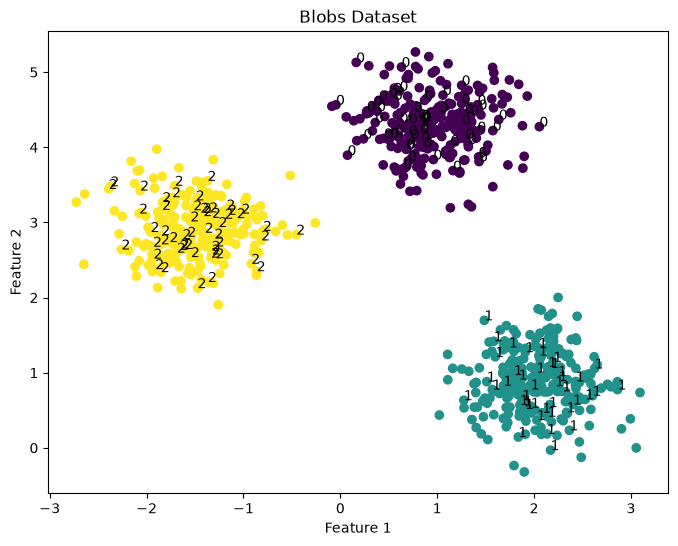

In [6]:
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c = y, cmap = 'viridis')
for i, txt in enumerate(y):
    if i%5 == 0:
        plt.annotate(txt, (X[i, 0], X[i, 1]))
plt.title('Blobs Dataset')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

#### Determine the $\epsilon$ parameter

We use the *k*-distance graph method to help choose an appropriate $\epsilon$ value:
1. We define a function <code>plot_k_distance_graph</code> that calculates the distance to the $k^{th}$ nearest neighbor for each point.
2. The distances are sorted and plotted.
3. We look for an "elbow" in the resulting graph to choose $\epsilon$.

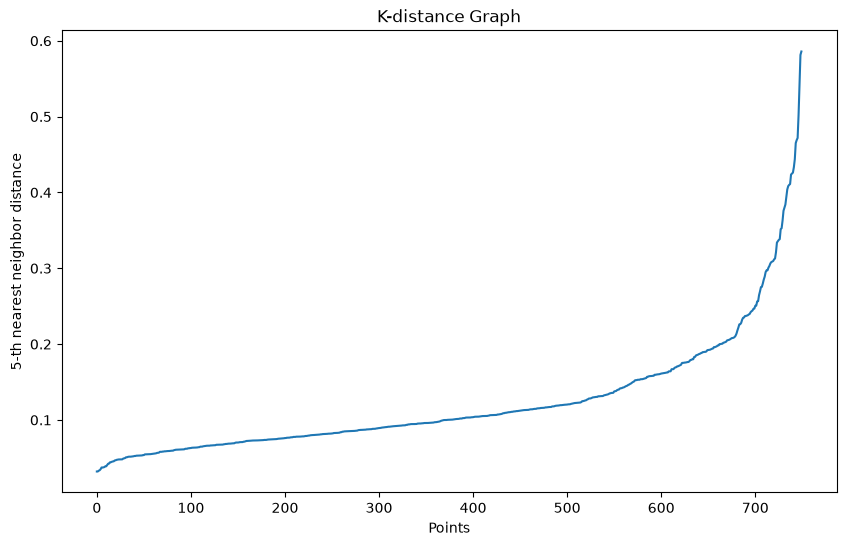

In [7]:
def plot_k_distance_graph(X, k):
    neigh = NearestNeighbors(n_neighbors=k)
    neigh.fit(X)
    distances, _ = neigh.kneighbors(X)
    distances = np.sort(distances[:, k-1])
    plt.figure(figsize=(10, 6))
    plt.plot(distances)
    plt.xlabel('Points')
    plt.ylabel(f'{k}-th nearest neighbor distance')
    plt.title('K-distance Graph')
    plt.show()
plot_k_distance_graph(X, k=5)

### Create the clusters

In [8]:
db = DBSCAN(eps=0.2, min_samples=10)

In [9]:
db.fit(X)

,"eps eps: float, default=0.5The maximum distance between two samples for one to be consideredas in the neighborhood of the other. This is not a maximum boundon the distances of points within a cluster. This is the mostimportant DBSCAN parameter to choose appropriately for your data setand distance function. Smaller values generally lead to more clusters.",0.2
,"min_samples min_samples: int, default=5The number of samples (or total weight) in a neighborhood for a point tobe considered as a core point. This includes the point itself. If`min_samples` is set to a higher value, DBSCAN will find denser clusters,whereas if it is set to a lower value, the found clusters will be moresparse.",10
,"metric metric: str, or callable, default='euclidean'The metric to use when calculating distance between instances in afeature array. If metric is a string or callable, it must be one ofthe options allowed by :func:`sklearn.metrics.pairwise_distances` forits metric parameter.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors for DBSCAN... versionadded:: 0.17 metric *precomputed* to accept precomputed sparse matrix.",'euclidean'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function... versionadded:: 0.19",None
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'The algorithm to be used by the NearestNeighbors moduleto compute pointwise distances and find nearest neighbors.'auto' will attempt to decide the most appropriate algorithmbased on the values passed to :meth:`fit` method.See :class:`~sklearn.neighbors.NearestNeighbors` documentation fordetails.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or cKDTree. This can affect the speedof the construction and query, as well as the memory requiredto store the tree. The optimal value dependson the nature of the problem.",30
,"p p: float, default=NoneThe power of the Minkowski metric to be used to calculate distancebetween points. If None, then ``p=2`` (equivalent to the Euclideandistance). When p=1, this is equivalent to Manhattan distance.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
"components_ components_: ndarray of shape (n_core_samples, n_features)Copy of each core sample found by training.","ndarray[float64](544, 2)","[[0.92,4.18], [1.64,0.72], [1.98,0.94], ..., [1.05,4.14], [2.17,1.59], [0.74,4.28]]"
"core_sample_indices_ core_sample_indices_: ndarray of shape (n_core_samples,)Indices of core samples.","ndarray[int64](544,)","[ 1, 2, 3,...,746,748,749]"


Confirm the associated labels shape

In [10]:
labels = db.labels_
labels.shape

(750,)

In [11]:
labels

array([-1,  0,  1,  1,  2, -1,  0, -1,  2, -1,  1, -1,  1, -1,  0,  1,  2,
       -1,  0, -1,  1,  1,  2,  1,  0,  0,  2,  2,  1,  1,  2,  1,  1,  1,
        0,  0,  2, -1,  0, -1,  2,  2,  1,  0, -1,  2,  0,  0,  2,  2,  0,
       -1,  2,  1,  2,  1,  1,  0,  0,  1,  2,  1,  0, -1,  2,  1,  2,  0,
        0,  2,  2,  2,  1, -1,  1,  2,  2,  1,  2, -1,  1,  0, -1,  0,  2,
       -1,  0,  0,  2,  2,  2,  0,  1,  1,  0,  2,  1,  2,  0,  0,  0,  0,
        0,  0,  1,  1,  2,  2,  1,  2,  0,  2,  1,  2,  1,  2,  1,  0,  1,
        0,  0,  1,  2,  1,  2,  2,  2,  0,  2, -1,  2,  2,  2,  1,  0,  2,
        0,  0,  0,  0,  1,  2,  2, -1,  1, -1,  2,  1,  1,  1,  2,  1, -1,
        1,  2,  2,  2, -1,  2,  0,  1,  2,  0,  1,  0,  2,  0,  2,  0,  1,
        0,  0,  0,  2,  2,  1,  2, -1,  2,  1,  0,  2,  2,  2,  2,  2,  1,
        2, -1,  2,  0,  1,  2,  0, -1,  2,  1,  1,  1,  0,  2,  0, -1,  2,
        2,  2,  0,  1,  1,  2,  1,  2,  1, -1,  1,  0, -1,  1,  0, -1,  0,
       -1,  2,  0,  2,  0

##### Interpret the results

Indices of core samples

In [12]:
db.core_sample_indices_

array([  1,   2,   3,   4,   6,   8,  10,  12,  14,  15,  16,  18,  20,
        21,  22,  23,  24,  25,  26,  27,  28,  29,  30,  32,  33,  34,
        35,  36,  40,  43,  46,  47,  48,  49,  52,  57,  58,  59,  60,
        61,  62,  65,  66,  67,  68,  69,  70,  71,  72,  74,  75,  76,
        78,  80,  83,  84,  86,  87,  89,  90,  92,  93,  94,  95,  96,
        97,  98, 101, 102, 103, 105, 106, 107, 108, 109, 110, 111, 112,
       113, 114, 115, 116, 117, 118, 119, 120, 121, 123, 125, 127, 128,
       130, 131, 132, 134, 135, 136, 137, 138, 139, 140, 141, 144, 146,
       147, 149, 150, 151, 153, 154, 155, 156, 158, 159, 160, 161, 162,
       163, 164, 165, 166, 167, 169, 170, 171, 172, 173, 174, 175, 176,
       178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 189, 190, 191,
       192, 193, 196, 197, 198, 199, 201, 203, 204, 205, 206, 207, 208,
       209, 210, 211, 214, 215, 217, 218, 220, 222, 225, 226, 227, 228,
       229, 230, 231, 232, 234, 235, 236, 238, 239, 240, 241, 24

Componentes

In [13]:
db.components_

array([[0.92311785, 4.18467098],
       [1.64221028, 0.72296432],
       [1.97590796, 0.93534058],
       ...,
       [1.04724054, 4.14307495],
       [2.16897939, 1.59473117],
       [0.73774446, 4.28276041]], shape=(544, 2))

No. of features

In [14]:
db.n_features_in_

2

Number of clusters in *labels* (ignoring noise if present)

In [15]:
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

In [16]:
print("Estimated number of clusters: %d" % n_clusters_)
print("Estimated number of noise points: %d" % n_noise_)

Estimated number of clusters: 3
Estimated number of noise points: 104


Obtain predictions

In [17]:
pred = db.fit_predict(X)

In [18]:
pred

array([-1,  0,  1,  1,  2, -1,  0, -1,  2, -1,  1, -1,  1, -1,  0,  1,  2,
       -1,  0, -1,  1,  1,  2,  1,  0,  0,  2,  2,  1,  1,  2,  1,  1,  1,
        0,  0,  2, -1,  0, -1,  2,  2,  1,  0, -1,  2,  0,  0,  2,  2,  0,
       -1,  2,  1,  2,  1,  1,  0,  0,  1,  2,  1,  0, -1,  2,  1,  2,  0,
        0,  2,  2,  2,  1, -1,  1,  2,  2,  1,  2, -1,  1,  0, -1,  0,  2,
       -1,  0,  0,  2,  2,  2,  0,  1,  1,  0,  2,  1,  2,  0,  0,  0,  0,
        0,  0,  1,  1,  2,  2,  1,  2,  0,  2,  1,  2,  1,  2,  1,  0,  1,
        0,  0,  1,  2,  1,  2,  2,  2,  0,  2, -1,  2,  2,  2,  1,  0,  2,
        0,  0,  0,  0,  1,  2,  2, -1,  1, -1,  2,  1,  1,  1,  2,  1, -1,
        1,  2,  2,  2, -1,  2,  0,  1,  2,  0,  1,  0,  2,  0,  2,  0,  1,
        0,  0,  0,  2,  2,  1,  2, -1,  2,  1,  0,  2,  2,  2,  2,  2,  1,
        2, -1,  2,  0,  1,  2,  0, -1,  2,  1,  1,  1,  0,  2,  0, -1,  2,
        2,  2,  0,  1,  1,  2,  1,  2,  1, -1,  1,  0, -1,  1,  0, -1,  0,
       -1,  2,  0,  2,  0

In [19]:
y

array([1, 0, 1, 1, 2, 2, 0, 0, 2, 2, 1, 0, 1, 0, 0, 1, 2, 1, 0, 2, 1, 1,
       2, 1, 0, 0, 2, 2, 1, 1, 2, 1, 1, 1, 0, 0, 2, 2, 0, 2, 2, 2, 1, 0,
       0, 2, 0, 0, 2, 2, 0, 2, 2, 1, 2, 1, 1, 0, 0, 1, 2, 1, 0, 1, 2, 1,
       2, 0, 0, 2, 2, 2, 1, 0, 1, 2, 2, 1, 2, 0, 1, 0, 0, 0, 2, 1, 0, 0,
       2, 2, 2, 0, 1, 1, 0, 2, 1, 2, 0, 0, 0, 0, 0, 0, 1, 1, 2, 2, 1, 2,
       0, 2, 1, 2, 1, 2, 1, 0, 1, 0, 0, 1, 2, 1, 2, 2, 2, 0, 2, 1, 2, 2,
       2, 1, 0, 2, 0, 0, 0, 0, 1, 2, 2, 1, 1, 0, 2, 1, 1, 1, 2, 1, 0, 1,
       2, 2, 2, 0, 2, 0, 1, 2, 0, 1, 0, 2, 0, 2, 0, 1, 0, 0, 0, 2, 2, 1,
       2, 2, 2, 1, 0, 2, 2, 2, 2, 2, 1, 2, 2, 2, 0, 1, 2, 0, 0, 2, 1, 1,
       1, 0, 2, 0, 1, 2, 2, 2, 0, 1, 1, 2, 1, 2, 1, 2, 1, 0, 0, 1, 0, 1,
       0, 0, 2, 0, 2, 0, 0, 1, 2, 1, 1, 0, 2, 2, 1, 1, 1, 1, 0, 0, 2, 0,
       0, 0, 1, 0, 1, 2, 1, 2, 2, 2, 0, 1, 2, 2, 1, 2, 1, 0, 1, 2, 1, 0,
       0, 2, 0, 1, 0, 2, 2, 2, 1, 1, 0, 0, 0, 1, 0, 0, 2, 1, 1, 2, 1, 2,
       2, 1, 2, 1, 2, 0, 1, 1, 0, 1, 1, 2, 2, 1, 2,

##### Visualize the resultant clusters

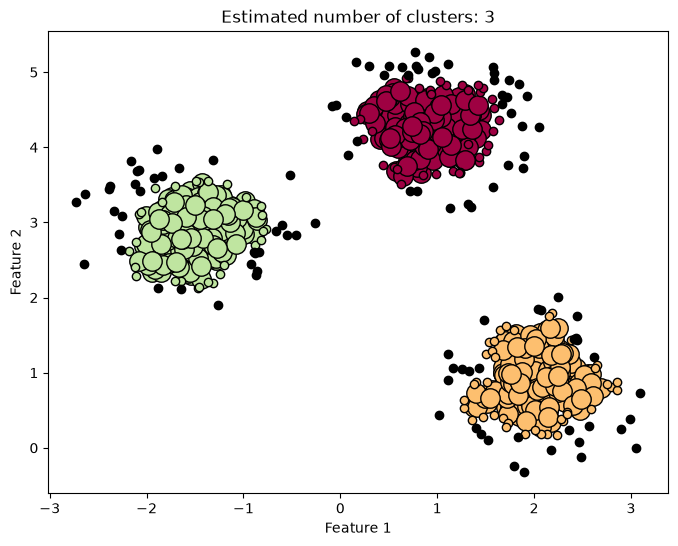

In [20]:
unique_labels = set(labels)
core_samples_mask = np.zeros_like(labels, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True

plt.figure(figsize=(8, 6))
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
for k, col in zip(unique_labels, colors):
    if k == -1:
        col = [0, 0, 0, 1]
    class_member_mask = labels == k
    xy = X[class_member_mask & core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], "o", markerfacecolor=tuple(col), markeredgecolor="k", markersize=14,)
    xy = X[class_member_mask & ~core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], "o", markerfacecolor=tuple(col), markeredgecolor="k", markersize=6,)
plt.title(f"Estimated number of clusters: {n_clusters_}")
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

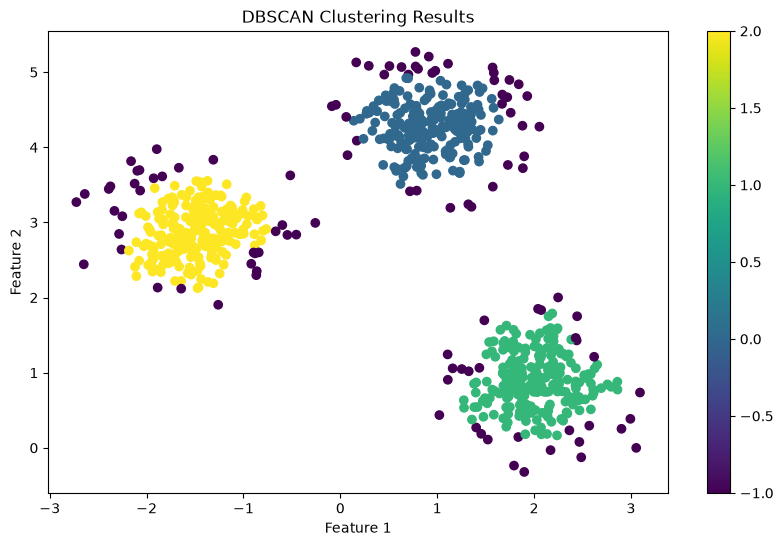

In [21]:
plt.figure(figsize=(10, 6))
scatter = plt.scatter(X[:, 0], X[:, 1], c=pred, cmap='viridis')
plt.colorbar(scatter)
plt.title('DBSCAN Clustering Results')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

#### Evaluate the model

##### Visualize the original vs. DBSCAN clusters

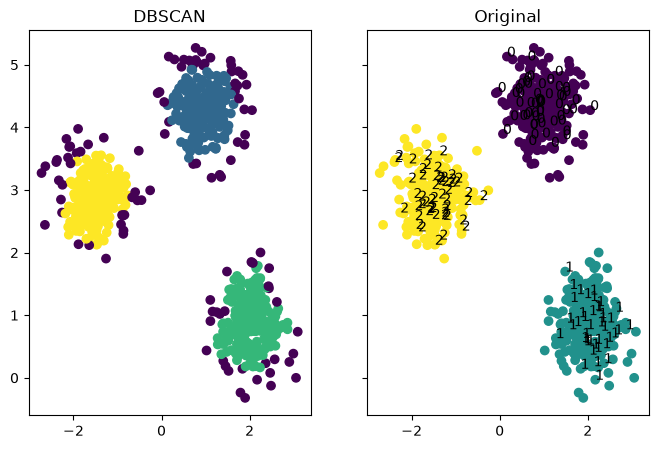

In [22]:
f, (ax1, ax2) = plt.subplots(1, 2, sharey=True,figsize=(8,5))
ax1.set_title("DBSCAN")
ax1.scatter(X[:, 0], X[:, 1], c = db.labels_, cmap = 'viridis')
ax2.set_title("Original")
ax2.scatter(X[:, 0], X[:, 1], c = y, cmap = 'viridis')
for i, txt in enumerate(y):
    if i%5 == 0:
        plt.annotate(txt, (X[i, 0], X[i, 1]))
plt.savefig("DBSCAN.png")
plt.show()

Because *Blobs* provides the true labels, we can analyze through the following metrics: homogeneity, completeness, V-measure, Adjusted Rand Index, Adjusted Mutual Information and Silhouette Coefficient

In [23]:
print(f"Homogeneity: {metrics.homogeneity_score(y, labels):.3f}")
print(f"Completeness: {metrics.completeness_score(y, labels):.3f}")
print(f"V-measure: {metrics.v_measure_score(y, labels):.3f}")
print(f"Adjusted Rand Index: {metrics.adjusted_rand_score(y, labels):.3f}")
print(f"Adjusted Mutual Information: {metrics.adjusted_mutual_info_score(y, labels):.3f}")
print(f"Silhouette Coefficient: {metrics.silhouette_score(X, labels):.3f}")

Homogeneity: 0.862
Completeness: 0.702
V-measure: 0.774
Adjusted Rand Index: 0.781
Adjusted Mutual Information: 0.773
Silhouette Coefficient: 0.586


In [24]:
print(confusion_matrix(y, pred))

[[  0   0   0   0]
 [ 39 211   0   0]
 [ 31   0 219   0]
 [ 34   0   0 216]]


In [25]:
print(classification_report(y, pred, zero_division=0))

              precision    recall  f1-score   support

          -1       0.00      0.00      0.00         0
           0       1.00      0.84      0.92       250
           1       1.00      0.88      0.93       250
           2       1.00      0.86      0.93       250

    accuracy                           0.86       750
   macro avg       0.75      0.65      0.69       750
weighted avg       1.00      0.86      0.93       750



#### Compare DBSCAN and K-Means

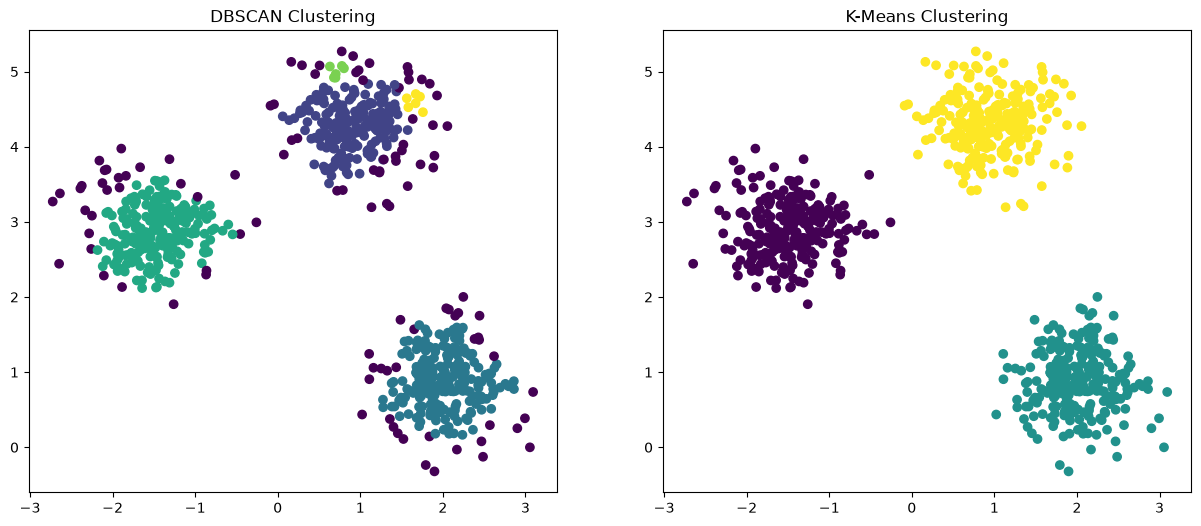

In [26]:
# DBSCAN clustering
dbscan = DBSCAN(eps=0.15, min_samples=5)
dbscan_labels = dbscan.fit_predict(X)

# K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans_labels = kmeans.fit_predict(X)

# Visualize the results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

ax1.scatter(X[:, 0], X[:, 1], c=dbscan_labels, cmap='viridis')
ax1.set_title('DBSCAN Clustering')

ax2.scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap='viridis')
ax2.set_title('K-Means Clustering')
plt.show()

In [27]:
print("Classification report")
print(f"DBSCAN: {classification_report(y, dbscan_labels, zero_division=0)}")
print(f"K-Means: {classification_report(y, kmeans_labels, zero_division=0)}\n")

Classification report
DBSCAN:               precision    recall  f1-score   support

          -1       0.00      0.00      0.00         0
           0       1.00      0.78      0.88       250
           1       1.00      0.86      0.92       250
           2       1.00      0.88      0.94       250
           3       0.00      0.00      0.00         0
           4       0.00      0.00      0.00         0

    accuracy                           0.84       750
   macro avg       0.50      0.42      0.46       750
weighted avg       1.00      0.84      0.91       750

K-Means:               precision    recall  f1-score   support

           0       0.00      0.00      0.00       250
           1       1.00      1.00      1.00       250
           2       0.00      0.00      0.00       250

    accuracy                           0.33       750
   macro avg       0.33      0.33      0.33       750
weighted avg       0.33      0.33      0.33       750




In [28]:
print("Homogeneity")
print(f"DBSCAN: {metrics.homogeneity_score(y, dbscan_labels):.3f}")
print(f"K-Means: {metrics.homogeneity_score(y, kmeans_labels):.3f}\n")

print("Completeness")
print(f"DBSCAN: {metrics.completeness_score(y, dbscan_labels):.3f}")
print(f"K-Means: {metrics.completeness_score(y, kmeans_labels):.3f}\n")

print("V-measure")
print(f"DBSCAN {metrics.v_measure_score(y, dbscan_labels):.3f}")
print(f"K-Means: {metrics.v_measure_score(y, kmeans_labels):.3f}\n")

print("Adjusted Rand Index")
print(f"DBSCAN: {metrics.adjusted_rand_score(y, dbscan_labels):.3f}")
print(f"K-Means: {metrics.adjusted_rand_score(y, kmeans_labels):.3f}\n")

print("Adjusted Mutual Information:")
print(f"DBSCAN: {metrics.adjusted_mutual_info_score(y, dbscan_labels):.3f}")
print(f"K-Means: {metrics.adjusted_mutual_info_score(y, kmeans_labels):.3f}\n")

print("Silhouette Coefficient")
print(f"DBSCAN: {metrics.silhouette_score(X, dbscan_labels):.3f}")
print(f"K-Means: {metrics.silhouette_score(X, kmeans_labels):.3f}\n")

print("Confusion Matrix")
print("DBSCAN"); print(confusion_matrix(y, dbscan_labels))
print("K-Means"); print(confusion_matrix(y, kmeans_labels))

Homogeneity
DBSCAN: 0.857
K-Means: 1.000

Completeness
DBSCAN: 0.661
K-Means: 1.000

V-measure
DBSCAN 0.747
K-Means: 1.000

Adjusted Rand Index
DBSCAN: 0.751
K-Means: 1.000

Adjusted Mutual Information:
DBSCAN: 0.745
K-Means: 1.000

Silhouette Coefficient
DBSCAN: 0.413
K-Means: 0.771

Confusion Matrix
DBSCAN
[[  0   0   0   0   0   0]
 [ 43 195   0   0   6   6]
 [ 35   0 215   0   0   0]
 [ 30   0   0 220   0   0]
 [  0   0   0   0   0   0]
 [  0   0   0   0   0   0]]
K-Means
[[  0   0 250]
 [  0 250   0]
 [250   0   0]]


In [29]:
# What about the labels? O nº de cada cluster do K-Means é arbitrário (na aula, o cluster 0 era a classe 2 e vice-versa).
# Corrigir: atribuir a cada cluster a classe real mais frequente nesse cluster
mapping = {c: np.bincount(y[kmeans_labels == c]).argmax() for c in np.unique(kmeans_labels)}
print('Mapeamento cluster -> classe:', mapping)
kmeans_labels = np.array([mapping[c] for c in kmeans_labels])

print("K-Means (with corrected labels)")
print(confusion_matrix(y, kmeans_labels))
print(classification_report(y, kmeans_labels, zero_division=0))

Mapeamento cluster -> classe: {np.int32(0): np.int64(2), np.int32(1): np.int64(1), np.int32(2): np.int64(0)}
K-Means (with corrected labels)
[[250   0   0]
 [  0 250   0]
 [  0   0 250]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       250
           1       1.00      1.00      1.00       250
           2       1.00      1.00      1.00       250

    accuracy                           1.00       750
   macro avg       1.00      1.00      1.00       750
weighted avg       1.00      1.00      1.00       750



#### Conclusões — *What conclusions can be drawn?*
- **As métricas de clustering não dependem do número dado a cada cluster.** Homogeneidade, completude, V-measure, ARI, AMI e Silhouette dão o mesmo valor antes e depois da correção. Só a matriz de confusão e o `classification_report` exigem alinhar as labels: o K-Means passa de accuracy 0.33 para **1.00** depois da correção.
- **Com os grupos esféricos e bem separados deste dataset, o K-Means é perfeito** (ARI = 1.0, Silhouette = 0.771), porque o número de clusters (3) é conhecido à partida.
- **O DBSCAN não precisa de saber o número de clusters, mas é sensível a `eps` e `min_samples`:**
  - com `eps=0.2` e `min_samples=10` encontra os 3 grupos e marca 104 pontos como ruído;
  - com `eps=0.15` e `min_samples=5` parte um dos grupos em sub-clusters extra (classes 3 e 4);
  - os pontos de ruído (-1) descem a completude (0.66–0.70) e o Silhouette (0.41–0.59).
- **O DBSCAN tem uma vantagem própria: deteta outliers** (label -1), que o K-Means é obrigado a atribuir a um cluster. Também consegue encontrar clusters de forma não esférica.
- **Escolha do modelo:** quando se conhece o número de grupos e eles são compactos, o K-Means é a melhor opção. Quando há ruído, formas irregulares ou se quer detetar anomalias, o DBSCAN é mais adequado.